# Preentrega 3 — Clasificación supervisada de noticias con TF-IDF

## Objetivo

Construir un clasificador de noticias AG News reutilizando el
preprocesamiento del módulo 2, comparar configuraciones de TF-IDF
y evaluar los resultados mediante precision, recall, F1 y matriz
de confusión.

Los datos se obtienen del repositorio público de GitHub.
El conjunto de prueba se reserva para la evaluación final.

## 1. Carga del dataset

Descargamos los archivos originales y el script de la cátedra desde
GitHub, manteniendo separados entrenamiento y prueba.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import importlib.util
import pandas as pd

REPO_URL = (
    "https://raw.githubusercontent.com/"
    "martingnegro/ag-news-text-classification/main"
)

PROJECT_DIR = Path("/content/ag-news-text-classification")
DATA_DIR = PROJECT_DIR / "data"

#Descargo los archivos conservando la estructura del repositorio.
required_files = [
    "data/cargar_dataset.py",
    "data/ag_news/ag_news_train.csv",
    "data/ag_news/ag_news_test.csv",
]

for relative_path in required_files:
    destination = PROJECT_DIR / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(f"{REPO_URL}/{relative_path}", destination)

#Importo el script de carga de la cátedra.
spec = importlib.util.spec_from_file_location(
    "cargar_dataset_catedra",
    DATA_DIR / "cargar_dataset.py"
)
dataset_loader = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dataset_loader)

train_df, test_df = dataset_loader.cargar("ag_news")

print(f"Noticias de entrenamiento: {len(train_df):,}")
print(f"Noticias de prueba: {len(test_df):,}")
print(f"Columnas: {train_df.columns.tolist()}")
print(f"Categorías: {sorted(train_df['label'].unique())}")

display(train_df.head())

Noticias de entrenamiento: 8,000
Noticias de prueba: 2,000
Columnas: ['text', 'label']
Categorías: ['Business', 'Sci_Tech', 'Sports', 'World']


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,Sports


## 2. Validación inicial de los datos

Verificamos columnas, textos válidos, etiquetas y duplicados.
Comprobamos coincidencias exactas entre entrenamiento y prueba
sin mezclar ambos conjuntos.

In [2]:
EXPECTED_COLUMNS = {"text", "label"}
CLASS_ORDER = ["World", "Sports", "Business", "Sci_Tech"]

checks = []

#Reviso la estructura y el contenido de ambos archivos.
for name, df in [("Entrenamiento", train_df), ("Prueba", test_df)]:
    assert set(df.columns) == EXPECTED_COLUMNS, (
        f"Columnas inesperadas en {name}."
    )

    null_texts = int(df["text"].isna().sum())

    invalid_texts = int(
        df["text"].map(
            lambda value: (
                not isinstance(value, str) and not pd.isna(value)
            )
        ).sum()
    )

    empty_texts = int(
        df["text"].map(
            lambda value: isinstance(value, str) and not value.strip()
        ).sum()
    )

    invalid_labels = int(
        (~df["label"].isin(CLASS_ORDER)).sum()
    )

    checks.append({
        "Conjunto": name,
        "Documentos": len(df),
        "Textos nulos": null_texts,
        "Textos vacíos": empty_texts,
        "Textos no válidos": invalid_texts,
        "Etiquetas no válidas": invalid_labels,
        "Filas duplicadas": int(df.duplicated().sum()),
        "Textos duplicados": int(df["text"].duplicated().sum())
    })

quality_summary = pd.DataFrame(checks)
display(quality_summary)

#Detengo el proceso si hay entradas que requieren corregirse.
problem_columns = [
    "Textos nulos",
    "Textos vacíos",
    "Textos no válidos",
    "Etiquetas no válidas"
]

assert quality_summary[problem_columns].to_numpy().sum() == 0, (
    "Se detectaron problemas en los datos. Revisar antes de continuar."
)

#Compruebo coincidencias exactas entre entrenamiento y prueba.
shared_texts = set(train_df["text"]) & set(test_df["text"])

print(
    "Textos exactamente iguales entre entrenamiento y prueba:",
    len(shared_texts)
)

assert not shared_texts, (
    "Hay textos compartidos entre entrenamiento y prueba."
)

#Muestro el balance de categorías en entrenamiento.
class_distribution = (
    train_df["label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
    .rename_axis("Categoría")
    .reset_index(name="Documentos")
)

class_distribution["Porcentaje (%)"] = (
    class_distribution["Documentos"] / len(train_df) * 100
).round(2)

display(class_distribution)

,Conjunto,Documentos,Textos nulos,Textos vacíos,Textos no válidos,Etiquetas no válidas,Filas duplicadas,Textos duplicados
0,Entrenamiento,8000,0,0,0,0,0,0
1,Prueba,2000,0,0,0,0,0,0


Textos exactamente iguales entre entrenamiento y prueba: 0


,Categoría,Documentos,Porcentaje (%)
0,World,2000,25.0
1,Sports,2000,25.0
2,Business,2000,25.0
3,Sci_Tech,2000,25.0


## 3. Configuración del preprocesamiento

Utilizamos el modelo de inglés en_core_web_sm de spaCy para tokenizar
y lematizar las noticias, siguiendo el procedimiento del módulo 2.
Registramos las versiones para documentar el entorno.

In [3]:
import sys
import subprocess

#Descargo el modelo con el Python del entorno.
subprocess.run(
    [sys.executable, "-m", "spacy", "download", "en_core_web_sm"],
    check=True
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'spacy', 'download', 'en_core_web_sm'], returncode=0)

In [4]:
import spacy

#Cargo el modelo sin reconocimiento de entidades.
nlp = spacy.load("en_core_web_sm", disable=["ner"])

print(f"Versión de spaCy: {spacy.__version__}")
print("Modelo: en_core_web_sm")
print(f"Versión del modelo: {nlp.meta['version']}")
print(f"Componentes activos: {nlp.pipe_names}")

#Compruebo la tokenización y la lematización.
sample = "The companies were developing new technologies."
doc = nlp(sample)

display(pd.DataFrame([
    {
        "Token": token.text,
        "Lema": token.lemma_,
        "Es stop-word": token.is_stop
    }
    for token in doc
    if not token.is_punct and not token.is_space
]))

Versión de spaCy: 3.8.18
Modelo: en_core_web_sm
Versión del modelo: 3.8.0
Componentes activos: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer']


,Token,Lema,Es stop-word
0,The,the,True
1,companies,company,False
2,were,be,True
3,developing,develop,False
4,new,new,False
5,technologies,technology,False


## 4. Pipeline de preprocesamiento

Reutilizamos la limpieza del módulo 2: reparación de entidades HTML,
eliminación de etiquetas y URLs, tratamiento del ruido editorial,
normalización a minúsculas y lematización con spaCy.

Conservamos números, negaciones y stop-words en esta representación.
El tratamiento de stop-words para TF-IDF se definirá en la vectorización.
Los textos originales permanecen intactos.

In [6]:
import re
import html
import unicodedata

HTML_PATTERN = re.compile(r"<[^>]+>")
URL_PATTERN = re.compile(
    r"\b(?:https?://|www\.)[^\s<>]+",
    flags=re.IGNORECASE
)
SPACE_PATTERN = re.compile(r"\s+")


def clean_text(text: str) -> str:
    if not isinstance(text, str):
        raise TypeError("El texto debe ser una cadena de caracteres.")

    #Decodifico entidades HTML, incluidas las escapadas dos veces.
    for _ in range(2):
        decoded = html.unescape(text)
        if decoded == text:
            break
        text = decoded

    #Reparo apóstrofos incompletos sin perder las negaciones.
    text = re.sub(
        r"\s*#(?:39|x27);",
        "'",
        text,
        flags=re.IGNORECASE
    )

    #Reparo otras entidades incompletas detectadas en el módulo 2.
    text = re.sub(
        r"(?<![\w&])(?:quot|amp|lt|gt|nbsp);",
        lambda match: html.unescape("&" + match.group(0)),
        text
    )

    text = unicodedata.normalize("NFC", text)
    text = HTML_PATTERN.sub(" ", text)
    text = URL_PATTERN.sub(" ", text)

    #Elimino la atribución duplicada entre título y descripción.
    text = re.sub(
        r"\(\s*AP\s*\)\s*\.\s*AP\s*[-–—]\s*",
        ". ",
        text,
        flags=re.IGNORECASE
    )

    #Retiro la navegación financiera y conservo el código bursátil.
    text = re.sub(
        r":\s*Quote\s*,\s*Profile\s*,\s*Research\s*(?=\))",
        "",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(r"\\[nrt]", " ", text)

    return SPACE_PATTERN.sub(" ", text.lower()).strip()


def preprocess_text(text: str) -> str:
    doc = nlp(clean_text(text))
    lemmas = []

    for token in doc:
        if token.is_space or token.is_punct:
            continue

        lemma = token.lemma_.strip().lower()

        #Conservo lemas que contienen letras o números.
        if lemma and any(character.isalnum() for character in lemma):
            lemmas.append(lemma)

    return " ".join(lemmas)

### Ejemplos antes y después

Inspeccionamos noticias de entrenamiento para mostrar cómo se reparan
caracteres, se elimina ruido editorial y se reducen variantes a lemas.

In [7]:
example_patterns = {
    "Atribución duplicada": (
        r"\(\s*AP\s*\)\s*\.\s*AP\s*[-–—]"
    ),
    "Navegación financiera": (
        r":\s*Quote\s*,\s*Profile\s*,\s*Research\s*(?=\))"
    ),
    "Apóstrofo mal codificado": r"#(?:39|x27);"
}

examples = []
selected_indices = set()

#Selecciono ejemplos de entrenamiento sin repetir noticias.
for case, pattern in example_patterns.items():
    mask = train_df["text"].str.contains(
        pattern,
        flags=re.IGNORECASE,
        regex=True,
        na=False
    )

    candidates = [
        index
        for index in train_df.index[mask]
        if index not in selected_indices
    ]

    if candidates:
        index = candidates[0]
        selected_indices.add(index)
        original = train_df.loc[index, "text"]

        examples.append({
            "Caso": case,
            "Categoría": train_df.loc[index, "label"],
            "Original": original,
            "Limpieza estructural": clean_text(original),
            "Preprocesado": preprocess_text(original)
        })

preprocessing_examples = pd.DataFrame(examples)

with pd.option_context("display.max_colwidth", None):
    display(preprocessing_examples)

#Compruebo la reparación de una negación con un ejemplo controlado.
negation_example = "The team hadn #39;t won."
negation_result = preprocess_text(negation_example)

assert "not" in negation_result.split(), (
    "La negación se perdió durante el procesamiento."
)

print("Ejemplo de negación:", negation_example)
print("Resultado:", negation_result)
print("Control de preservación de la negación: correcto.")

,Caso,Categoría,Original,Limpieza estructural,Preprocesado
0,Atribución duplicada,Sci_Tech,"U.N. to Debate Anti-Cloning Treaty (AP). AP - The highly contentious issue of cloning is back on the U.N. agenda, with support among member states for a treaty banning human cloning but divisions over the use of human embryos for medical research.","u.n. to debate anti-cloning treaty . the highly contentious issue of cloning is back on the u.n. agenda, with support among member states for a treaty banning human cloning but divisions over the use of human embryos for medical research.",u.n to debate anti cloning treaty the highly contentious issue of cloning be back on the u.n agenda with support among member state for a treaty ban human cloning but division over the use of human embryo for medical research
1,Navegación financiera,Business,"UPDATE 1-Warburg Pincus to buy 2.75 of Kotak Mahindra Bank. The board of India #39;s Kotak Mahindra Bank Ltd. (KTKM.BO: Quote, Profile, Research) has approved an issue of shares representing a 2.75 percent stake to Warburg Pincus International LLC.",update 1-warburg pincus to buy 2.75 of kotak mahindra bank. the board of india's kotak mahindra bank ltd. (ktkm.bo) has approved an issue of shares representing a 2.75 percent stake to warburg pincus international llc.,update 1 warburg pincus to buy 2.75 of kotak mahindra bank the board of india 's kotak mahindra bank ltd ktkm.bo have approve an issue of share represent a 2.75 percent stake to warburg pincus international llc
2,Apóstrofo mal codificado,Business,"WorldCom, Microsoft cases before EU court. Two of the European Union #39;s landmark antitrust decisions against US companies are in court this week as WorldCom Inc. seeks a moral victory and Microsoft Corp.","worldcom, microsoft cases before eu court. two of the european union's landmark antitrust decisions against us companies are in court this week as worldcom inc. seeks a moral victory and microsoft corp.",worldcom microsoft case before eu court two of the european union 's landmark antitrust decision against us company be in court this week as worldcom inc seek a moral victory and microsoft corp


Ejemplo de negación: The team hadn #39;t won.
Resultado: the team have not win
Control de preservación de la negación: correcto.


## 5. Preprocesamiento del conjunto de entrenamiento

Aplicamos las mismas reglas a las 8.000 noticias, conservando los textos
originales. Comprobamos documentos vacíos, residuos conocidos y textos
equivalentes después de la normalización.

Los textos equivalentes se identificarán como grupos para mantenerlos
juntos al separar entrenamiento y validación.

In [8]:
from tqdm.auto import tqdm

#Conservo el corpus original.
train_processed = train_df.copy()

tqdm.pandas(desc="Procesando entrenamiento")

train_processed["text_preprocessed"] = (
    train_processed["text"].progress_apply(preprocess_text)
)

train_processed["token_count"] = (
    train_processed["text_preprocessed"].str.split().str.len()
)

#Identifico los textos que quedaron iguales.
train_processed["text_group"] = pd.factorize(
    train_processed["text_preprocessed"],
    sort=True
)[0]

empty_documents = int(
    train_processed["token_count"].eq(0).sum()
)

duplicate_processed = int(
    train_processed["text_preprocessed"].duplicated().sum()
)

#Reviso los residuos detectados en el módulo anterior.
residual_patterns = {
    "Codificación incompleta": (
        r"(?:#?39;|#?x27;|\b(?:quot|amp|lt|gt|nbsp);)"
    ),
    "Atribución duplicada": r"(?<!\S)ap ap(?!\S)",
    "Navegación financiera": (
        r"(?<!\S)quote profile research(?!\S)"
    )
}

residual_checks = []

for name, pattern in residual_patterns.items():
    mask = train_processed["text_preprocessed"].str.contains(
        pattern,
        flags=re.IGNORECASE,
        regex=True,
        na=False
    )

    residual_checks.append({
        "Control": name,
        "Documentos detectados": int(mask.sum())
    })

residual_summary = pd.DataFrame(residual_checks)

print(f"Documentos procesados: {len(train_processed):,}")
print(f"Documentos vacíos: {empty_documents}")
print(f"Repeticiones adicionales: {duplicate_processed}")
print(
    "Textos procesados únicos:",
    f"{train_processed['text_preprocessed'].nunique():,}"
)
print(
    "Total de tokens:",
    f"{train_processed['token_count'].sum():,}"
)

display(residual_summary)

assert len(train_processed) == len(train_df), (
    "Cambió la cantidad de documentos."
)

assert empty_documents == 0, (
    "Hay documentos vacíos después del procesamiento."
)

assert residual_summary["Documentos detectados"].sum() == 0, (
    "Se detectaron residuos que requieren revisión."
)

#Reviso si algún texto equivalente tiene etiquetas contradictorias.
labels_per_group = (
    train_processed.groupby("text_group")["label"].nunique()
)

conflicting_groups = labels_per_group[labels_per_group > 1]

print(
    "Grupos con etiquetas contradictorias:",
    len(conflicting_groups)
)

assert conflicting_groups.empty, (
    "Hay textos equivalentes con etiquetas distintas."
)

#Resumo los grupos de noticias repetidas.
duplicate_mask = train_processed[
    "text_preprocessed"
].duplicated(keep=False)

duplicate_summary = (
    train_processed.loc[duplicate_mask]
    .groupby("text_group")
    .agg(
        Documentos=("label", "size"),
        Categorías=(
            "label",
            lambda values: ", ".join(sorted(set(values)))
        ),
        Texto_procesado=("text_preprocessed", "first")
    )
    .reset_index()
)

display(duplicate_summary)

Procesando entrenamiento:   0%|          | 0/8000 [00:00<?, ?it/s]

Documentos procesados: 8,000
Documentos vacíos: 0
Repeticiones adicionales: 2
Textos procesados únicos: 7,998
Total de tokens: 304,571


,Control,Documentos detectados
0,Codificación incompleta,0
1,Atribución duplicada,0
2,Navegación financiera,0


Grupos con etiquetas contradictorias: 0


,text_group,Documentos,Categorías,Texto_procesado
0,4092,2,Sci_Tech,lowe 's hardware hacker get nine year one of t...
1,4831,2,Sci_Tech,newfound comet set for winter display space.co...


## 6. Separación de entrenamiento y validación

Reservamos aproximadamente el 20 % del entrenamiento para validación,
manteniendo la proporción de categorías y agrupando los textos equivalentes.

Esta partición permite seleccionar los parámetros de TF-IDF sin utilizar
el conjunto de prueba. Fijamos una semilla para reproducir la separación.

In [9]:
from sklearn.model_selection import train_test_split

SEED = 42

#Obtengo una fila por grupo de textos equivalentes.
group_labels = (
    train_processed[["text_group", "label"]]
    .drop_duplicates(subset="text_group")
)

#Divido los grupos manteniendo la proporción de categorías.
train_group_ids, validation_group_ids = train_test_split(
    group_labels["text_group"].to_numpy(),
    test_size=0.20,
    random_state=SEED,
    stratify=group_labels["label"]
)

#Recupero todos los documentos de cada grupo.
train_internal = train_processed.loc[
    train_processed["text_group"].isin(train_group_ids)
].copy()

validation_df = train_processed.loc[
    train_processed["text_group"].isin(validation_group_ids)
].copy()

#Compruebo que no haya grupos ni textos compartidos.
shared_groups = (
    set(train_internal["text_group"])
    & set(validation_df["text_group"])
)

shared_processed_texts = (
    set(train_internal["text_preprocessed"])
    & set(validation_df["text_preprocessed"])
)

assert not shared_groups, (
    "Hay grupos compartidos entre entrenamiento y validación."
)

assert not shared_processed_texts, (
    "Hay textos equivalentes en ambos conjuntos."
)

assert len(train_internal) + len(validation_df) == len(train_processed), (
    "La partición perdió o duplicó documentos."
)

assert set(train_internal["label"]) == set(CLASS_ORDER)
assert set(validation_df["label"]) == set(CLASS_ORDER)

print(f"Entrenamiento interno: {len(train_internal):,} noticias")
print(f"Validación: {len(validation_df):,} noticias")
print(f"Prueba reservada: {len(test_df):,} noticias")
print(f"Grupos compartidos: {len(shared_groups)}")
print(f"Textos procesados compartidos: {len(shared_processed_texts)}")

#Comparo la distribución de categorías.
split_summary = pd.DataFrame({
    "Entrenamiento": (
        train_internal["label"].value_counts()
        .reindex(CLASS_ORDER, fill_value=0)
    ),
    "Validación": (
        validation_df["label"].value_counts()
        .reindex(CLASS_ORDER, fill_value=0)
    )
})

split_summary["Entrenamiento (%)"] = (
    split_summary["Entrenamiento"] / len(train_internal) * 100
).round(2)

split_summary["Validación (%)"] = (
    split_summary["Validación"] / len(validation_df) * 100
).round(2)

split_summary = (
    split_summary.rename_axis("Categoría").reset_index()
)

display(split_summary)

#Defino las entradas y las etiquetas para el modelado.
X_train_text = train_internal["text_preprocessed"]
y_train = train_internal["label"]

X_val_text = validation_df["text_preprocessed"]
y_val = validation_df["label"]

Entrenamiento interno: 6,400 noticias
Validación: 1,600 noticias
Prueba reservada: 2,000 noticias
Grupos compartidos: 0
Textos procesados compartidos: 0


,Categoría,Entrenamiento,Validación,Entrenamiento (%),Validación (%)
0,World,1600,400,25.0,25.0
1,Sports,1600,400,25.0,25.0
2,Business,1600,400,25.0,25.0
3,Sci_Tech,1600,400,25.0,25.0


## 7. Experimentación con TF-IDF y Regresión Logística

Comparamos vocabularios de hasta 5.000 y 10.000 características,
utilizando unigramas o unigramas y bigramas.

Usamos Regresión Logística por su adecuación a representaciones
esparsas de texto y la posibilidad de interpretar sus coeficientes.
Mantenemos sus parámetros constantes para comparar los vectorizadores.

Cada vectorizador se ajusta únicamente sobre entrenamiento interno.
Seleccionamos la configuración mediante F1 macro en validación,
que asigna la misma importancia a las cuatro categorías.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
from time import perf_counter

#Filtro stop-words sobre los lemas y conservo negaciones explícitas.
negations = {"no", "not", "nor", "never"}
stop_words_tfidf = sorted(set(nlp.Defaults.stop_words) - negations)

configurations = [
    {"max_features": 5000, "ngram_range": (1, 1)},
    {"max_features": 5000, "ngram_range": (1, 2)},
    {"max_features": 10000, "ngram_range": (1, 1)},
    {"max_features": 10000, "ngram_range": (1, 2)}
]

experiment_results = []
trained_pipelines = {}

for config in configurations:
    experiment_id = (
        f"tfidf_{config['max_features']}_"
        f"{config['ngram_range'][0]}_{config['ngram_range'][1]}"
    )

    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                tokenizer=str.split,
                token_pattern=None,
                lowercase=False,
                stop_words=stop_words_tfidf,
                max_features=config["max_features"],
                ngram_range=config["ngram_range"]
            )
        ),
        (
            "classifier",
            LogisticRegression(
                C=1.0,
                solver="lbfgs",
                max_iter=2000,
                random_state=SEED
            )
        )
    ])

    #Ajusto vocabulario, pesos TF-IDF y clasificador solo con entrenamiento.
    start = perf_counter()
    pipeline.fit(X_train_text, y_train)
    training_seconds = perf_counter() - start

    #En validación, el pipeline solo transforma y predice.
    predictions = pipeline.predict(X_val_text)

    experiment_results.append({
        "Experimento": experiment_id,
        "max_features": config["max_features"],
        "ngram_range": str(config["ngram_range"]),
        "Características reales": len(
            pipeline.named_steps["tfidf"].vocabulary_
        ),
        "Accuracy validación": accuracy_score(y_val, predictions),
        "F1 macro validación": f1_score(
            y_val,
            predictions,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        ),
        "Tiempo entrenamiento (s)": training_seconds
    })

    trained_pipelines[experiment_id] = pipeline

    print(f"Completado: {experiment_id}")

#Ordeno por F1 macro y, ante igualdad, prefiero menor vocabulario.
comparison_df = (
    pd.DataFrame(experiment_results)
    .sort_values(
        [
            "F1 macro validación",
            "Características reales",
            "ngram_range"
        ],
        ascending=[False, True, True],
        kind="stable"
    )
    .reset_index(drop=True)
)

display(comparison_df.round({
    "Accuracy validación": 4,
    "F1 macro validación": 4,
    "Tiempo entrenamiento (s)": 2
}))

Completado: tfidf_5000_1_1
Completado: tfidf_5000_1_2
Completado: tfidf_10000_1_1
Completado: tfidf_10000_1_2


,Experimento,max_features,ngram_range,Características reales,Accuracy validación,F1 macro validación,Tiempo entrenamiento (s)
0,tfidf_10000_1_2,10000,"(1, 2)",10000,0.8862,0.8857,3.04
1,tfidf_5000_1_2,5000,"(1, 2)",5000,0.8838,0.8833,3.47
2,tfidf_10000_1_1,10000,"(1, 1)",10000,0.8806,0.8800,4.83
3,tfidf_5000_1_1,5000,"(1, 1)",5000,0.8756,0.8750,2.40


### Interpretación de los experimentos

La configuración con 10.000 características y unigramas más bigramas
obtuvo el mayor F1 macro de validación (0,8857), frente a 0,8833 con
5.000 características y el mismo rango de n-gramas.

Los bigramas mejoraron el resultado con ambos límites de vocabulario,
lo que sugiere que las combinaciones de términos aportan información
útil para distinguir categorías en esta partición.

Seleccionamos la configuración con mayor F1 macro, sin utilizar
el conjunto de prueba para tomar esta decisión.

## 8. Evaluación por categoría en validación

Evaluamos la configuración seleccionada mediante precision, recall
y F1 por categoría. Estos resultados permiten identificar diferencias
que no se observan en las métricas globales.

In [11]:
from sklearn.metrics import classification_report

#Recupero la configuración seleccionada sin volver a entrenarla.
best_experiment_id = comparison_df.loc[0, "Experimento"]
best_pipeline = trained_pipelines[best_experiment_id]

validation_predictions = best_pipeline.predict(X_val_text)

print(f"Configuración seleccionada: {best_experiment_id}")
print(
    "Máximo de características:",
    best_pipeline.named_steps["tfidf"].max_features
)
print(
    "Rango de n-gramas:",
    best_pipeline.named_steps["tfidf"].ngram_range
)

print("\nReporte de clasificación — Validación")
print(classification_report(
    y_val,
    validation_predictions,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    digits=4,
    zero_division=0
))

#Guardo el reporte como tabla para exportarlo después.
validation_report_df = pd.DataFrame(
    classification_report(
        y_val,
        validation_predictions,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        output_dict=True,
        zero_division=0
    )
).transpose()

Configuración seleccionada: tfidf_10000_1_2
Máximo de características: 10000
Rango de n-gramas: (1, 2)

Reporte de clasificación — Validación
              precision    recall  f1-score   support

       World     0.8980    0.9025    0.9002       400
      Sports     0.9372    0.9700    0.9533       400
    Business     0.8460    0.8375    0.8417       400
    Sci_Tech     0.8608    0.8350    0.8477       400

    accuracy                         0.8862      1600
   macro avg     0.8855    0.8862    0.8857      1600
weighted avg     0.8855    0.8862    0.8857      1600



### Matriz de confusión de validación

Las filas representan las categorías reales y las columnas las
predicciones. Cada celda muestra la cantidad de noticias y el porcentaje
respecto del total de su categoría real.

La diagonal contiene las predicciones correctas; las demás celdas
permiten identificar las confusiones entre categorías.

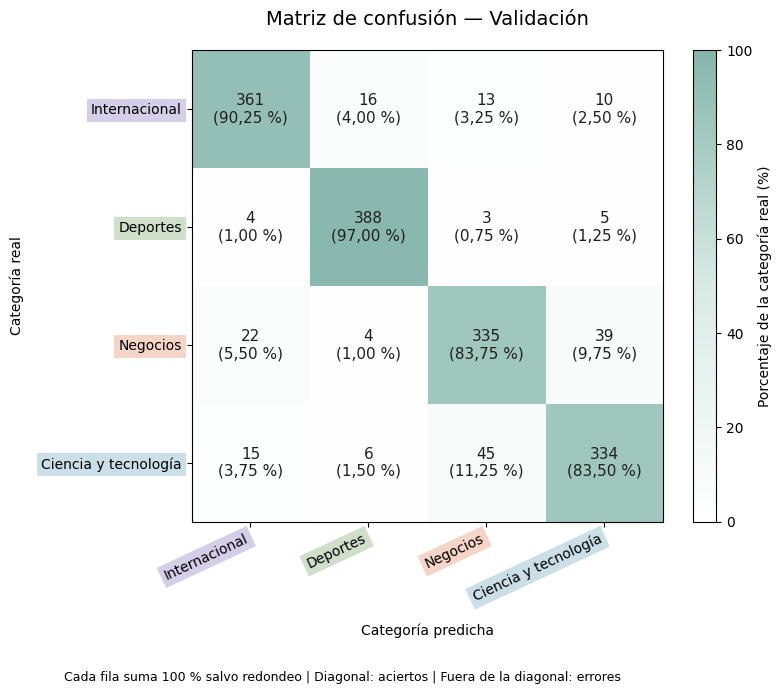

,Categoría real,Predicción incorrecta,Noticias,Porcentaje de la clase real (%)
0,Sci_Tech,Business,45,11.25
1,Business,Sci_Tech,39,9.75
2,Business,World,22,5.50
3,World,Sports,16,4.00
4,Sci_Tech,World,15,3.75
5,World,Business,13,3.25
6,World,Sci_Tech,10,2.50
7,Sci_Tech,Sports,6,1.50
8,Sports,Sci_Tech,5,1.25
9,Business,Sports,4,1.00


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

CLASS_COLORS = {
    "World": "#B4A7D6",
    "Sports": "#A8C5A0",
    "Business": "#EDB49A",
    "Sci_Tech": "#9FC5D5"
}

CLASS_NAMES_ES = {
    "World": "Internacional",
    "Sports": "Deportes",
    "Business": "Negocios",
    "Sci_Tech": "Ciencia y tecnología"
}

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

#Uso una escala común para representar la intensidad de las celdas.
confusion_cmap = LinearSegmentedColormap.from_list(
    "confusion_pastel",
    ["#FFFFFF", "#D8EBE6", "#85B6AB"]
)


def plot_confusion_matrix(y_true, y_pred, title, filename):
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_ORDER
    )

    row_totals = matrix.sum(axis=1, keepdims=True)

    percentages = np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix, dtype=float),
        where=row_totals != 0
    ) * 100

    labels = [CLASS_NAMES_ES[label] for label in CLASS_ORDER]

    fig, ax = plt.subplots(figsize=(9, 7))

    plot = ax.imshow(
        percentages,
        cmap=confusion_cmap,
        vmin=0,
        vmax=100
    )

    ax.set_xticks(range(len(CLASS_ORDER)))
    ax.set_yticks(range(len(CLASS_ORDER)))
    ax.set_xticklabels(labels, rotation=25, ha="right")
    ax.set_yticklabels(labels)

    #Mantengo los colores por categoría como fondo de las etiquetas.
    for tick_labels in [ax.get_xticklabels(), ax.get_yticklabels()]:
        for tick, category in zip(tick_labels, CLASS_ORDER):
            tick.set_bbox({
                "facecolor": CLASS_COLORS[category],
                "edgecolor": "none",
                "alpha": 0.55,
                "pad": 3
            })

    #Muestro cantidades y porcentajes dentro de cada celda.
    for row in range(len(CLASS_ORDER)):
        for column in range(len(CLASS_ORDER)):
            percentage_text = (
                f"{percentages[row, column]:.2f}".replace(".", ",")
            )

            ax.text(
                column,
                row,
                f"{matrix[row, column]}\n({percentage_text} %)",
                ha="center",
                va="center",
                fontsize=11,
                color="#202020"
            )

    ax.set_xlabel("Categoría predicha", labelpad=14)
    ax.set_ylabel("Categoría real", labelpad=12)
    ax.set_title(title, fontsize=14, pad=18)

    colorbar = fig.colorbar(plot, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label("Porcentaje de la categoría real (%)")

    fig.text(
        0.5,
        0.02,
        "Cada fila suma 100 % salvo redondeo | "
        "Diagonal: aciertos | Fuera de la diagonal: errores",
        ha="center",
        fontsize=9
    )

    fig.tight_layout(rect=[0, 0.06, 1, 1])
    fig.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return matrix


validation_cm = plot_confusion_matrix(
    y_val,
    validation_predictions,
    "Matriz de confusión — Validación",
    "01_matriz_confusion_validacion.png"
)

#Ordeno las confusiones por cantidad de noticias.
confusion_rows = []

for row, actual_class in enumerate(CLASS_ORDER):
    for column, predicted_class in enumerate(CLASS_ORDER):
        count = int(validation_cm[row, column])

        if row != column and count > 0:
            confusion_rows.append({
                "Categoría real": actual_class,
                "Predicción incorrecta": predicted_class,
                "Noticias": count,
                "Porcentaje de la clase real (%)": (
                    count / validation_cm[row].sum() * 100
                )
            })

validation_confusions_df = pd.DataFrame(
    confusion_rows,
    columns=[
        "Categoría real",
        "Predicción incorrecta",
        "Noticias",
        "Porcentaje de la clase real (%)"
    ]
).sort_values(
    ["Noticias", "Categoría real", "Predicción incorrecta"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(validation_confusions_df.round(2))

### Interpretación de los errores de validación

La confusión entre Negocios y Ciencia/Tecnología concentra 84 de los
182 errores (46,15 %), mientras que Deportes presenta el mayor recall
(97 %).

Una posible explicación es el vocabulario compartido en noticias sobre
empresas tecnológicas, mercados y productos; revisamos ejemplos reales
para contrastar esta hipótesis.

In [13]:
#Relaciono cada predicción con su noticia original.
validation_review = validation_df[
    ["text", "text_preprocessed", "label"]
].copy()

validation_review["Predicción"] = validation_predictions

validation_errors = validation_review.loc[
    validation_review["label"] != validation_review["Predicción"]
].copy()

#Selecciono ejemplos reproducibles de las dos confusiones principales.
confusion_pairs = [
    ("Sci_Tech", "Business"),
    ("Business", "Sci_Tech")
]

selected_examples = []

for actual_class, predicted_class in confusion_pairs:
    candidates = validation_errors.loc[
        (validation_errors["label"] == actual_class)
        & (validation_errors["Predicción"] == predicted_class)
    ]

    selected_examples.append(
        candidates.sample(
            n=min(3, len(candidates)),
            random_state=SEED
        )
    )

error_examples = pd.concat(selected_examples).rename(
    columns={
        "text": "Texto original",
        "text_preprocessed": "Texto preprocesado",
        "label": "Categoría real"
    }
)

with pd.option_context("display.max_colwidth", None):
    display(
        error_examples[
            ["Categoría real", "Predicción", "Texto original"]
        ]
    )

print(f"Errores totales de validación: {len(validation_errors)}")

,Categoría real,Predicción,Texto original
7349,Sci_Tech,Business,Diebold cuts forecast. Diebold Inc. today reduced its third-quarter and full-year earnings forecasts as it absorbs costs for recertifying its electronic voting machines in California and for expenses related to a pending civil action in that state.
4995,Sci_Tech,Business,Comcast Subpoenas Elected Leaders In Montgomery Who Favored Union. Two Montgomery County Council members who supported a campaign by employees of Comcast Cable Communications to form a union have been subpoenaed by company attorneys in a federal labor relations case involving a Rockville man who says he was illegally fired by the firm.
5032,Sci_Tech,Business,"Intel Pentium 4 prices slashed by 35. The price of the Pentium 4 560 is now priced at $417 from $637, while prices of other desktop Pentium 4 chips are cut by 18 percent to 33 percent."
7343,Business,Sci_Tech,"Atlanta Named Third Most Dangerous City. A Kansas company #39;s yearly ranking based on crime statistics shows that Camden, New Jersey, has become the nation #39;s most-dangerous city."
7597,Business,Sci_Tech,"Adobe to update PDF tools. Put away the red pen, because publishing software giant Adobe Systems plans to change the way businesses share comments on documents."
1648,Business,Sci_Tech,"Modern technology for an ancient sport. One sport that relies increasingly on GPS technology is horseback riding ( quot;Space-age sport, quot; Aug. 16). Horseback riders who practice trail riding for pleasure, or the more demanding cross country sports, are beginning to use GPS in large numbers."


Errores totales de validación: 182


### Revisión cualitativa de errores

Los ejemplos muestran solapamiento temático: noticias etiquetadas como
Sci_Tech incluyen ganancias, precios y conflictos laborales, mientras
que algunas noticias Business describen software y tecnología GPS.

También aparecen etiquetas cuya relación con el contenido no resulta
evidente, como Business en una noticia sobre criminalidad; se conservan
las etiquetas originales y se documentan estos casos para revisión.

Esta inspección ilustra posibles causas de error, pero no demuestra qué
términos determinaron cada predicción ni permite generalizar a todos
los errores.

## 9. Reentrenamiento de la configuración seleccionada

Con los parámetros definidos mediante validación, entrenamos una nueva
instancia del pipeline sobre las 8.000 noticias del archivo de
entrenamiento.

El vocabulario, los pesos TF-IDF y los parámetros del clasificador se
aprenden nuevamente sobre ese conjunto completo. El test no participa
en este ajuste.

In [14]:
from sklearn.base import clone

#Creo una instancia sin entrenar con los parámetros seleccionados.
final_pipeline = clone(best_pipeline)

#Ajusto el pipeline usando todo el entrenamiento disponible.
start = perf_counter()

final_pipeline.fit(
    train_processed["text_preprocessed"],
    train_processed["label"]
)

final_training_seconds = perf_counter() - start

print(f"Configuración: {best_experiment_id}")
print(f"Noticias utilizadas: {len(train_processed):,}")
print(
    "Características del vocabulario final:",
    len(final_pipeline.named_steps["tfidf"].vocabulary_)
)
print(
    f"Tiempo de entrenamiento: {final_training_seconds:.2f} segundos"
)
print("Conjunto de prueba utilizado en el ajuste: no.")

Configuración: tfidf_10000_1_2
Noticias utilizadas: 8,000
Características del vocabulario final: 10000
Tiempo de entrenamiento: 3.34 segundos
Conjunto de prueba utilizado en el ajuste: no.


## 10. Evaluación final sobre el conjunto de prueba

Aplicamos el preprocesamiento previamente definido a las 2.000 noticias
de prueba y verificamos documentos vacíos y coincidencias con los textos
procesados de entrenamiento.

El pipeline utiliza el vocabulario y los parámetros aprendidos sobre
entrenamiento para predecir las categorías del test. Los resultados se
reportan sin utilizarlos para modificar la configuración seleccionada.

In [17]:
#Aplico al test las mismas reglas, sin modificar los originales.
test_processed = test_df.copy()

tqdm.pandas(desc="Procesando prueba")

test_processed["text_preprocessed"] = (
    test_processed["text"].progress_apply(preprocess_text)
)

empty_test_documents = int(
    test_processed["text_preprocessed"].str.strip().eq("").sum()
)

#Reviso coincidencias que podrían aparecer después de normalizar.
shared_processed_test = (
    set(train_processed["text_preprocessed"])
    & set(test_processed["text_preprocessed"])
)

overlapping_test_documents = int(
    test_processed["text_preprocessed"]
    .isin(shared_processed_test)
    .sum()
)

print(f"Noticias de prueba procesadas: {len(test_processed):,}")
print(f"Documentos vacíos: {empty_test_documents}")
print(
    "Noticias de prueba equivalentes a textos de entrenamiento:",
    overlapping_test_documents
)

assert empty_test_documents == 0, (
    "Hay documentos de prueba vacíos después del procesamiento."
)

if overlapping_test_documents > 0:
    print(
        "Advertencia: existen coincidencias procesadas entre "
        "entrenamiento y prueba. Se reportarán métricas sobre el "
        "test completo y sobre el subconjunto sin coincidencias."
    )

#Predigo sin ajustar nuevamente TF-IDF ni el clasificador.
test_predictions = final_pipeline.predict(
    test_processed["text_preprocessed"]
)

test_accuracy = accuracy_score(
    test_processed["label"],
    test_predictions
)

test_f1_macro = f1_score(
    test_processed["label"],
    test_predictions,
    labels=CLASS_ORDER,
    average="macro",
    zero_division=0
)

test_f1_weighted = f1_score(
    test_processed["label"],
    test_predictions,
    labels=CLASS_ORDER,
    average="weighted",
    zero_division=0
)

print(f"\nAccuracy de prueba: {test_accuracy:.4f}")
print(f"F1 macro de prueba: {test_f1_macro:.4f}")
print(f"F1 weighted de prueba: {test_f1_weighted:.4f}")

print("\nReporte de clasificación — Prueba")
print(classification_report(
    test_processed["label"],
    test_predictions,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    digits=4,
    zero_division=0
))

#Guardo las métricas y predicciones para su exportación posterior.
test_report_df = pd.DataFrame(
    classification_report(
        test_processed["label"],
        test_predictions,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        output_dict=True,
        zero_division=0
    )
).transpose()

test_predictions_df = test_processed[
    ["text", "label"]
].copy()

test_predictions_df["Predicción"] = test_predictions
test_predictions_df["Correcta"] = (
    test_predictions_df["label"]
    == test_predictions_df["Predicción"]
)

Procesando prueba:   0%|          | 0/2000 [00:00<?, ?it/s]

Noticias de prueba procesadas: 2,000
Documentos vacíos: 0
Noticias de prueba equivalentes a textos de entrenamiento: 2
Advertencia: existen coincidencias procesadas entre entrenamiento y prueba. Se reportarán métricas sobre el test completo y sobre el subconjunto sin coincidencias.

Accuracy de prueba: 0.8910
F1 macro de prueba: 0.8910
F1 weighted de prueba: 0.8910

Reporte de clasificación — Prueba
              precision    recall  f1-score   support

       World     0.9076    0.8840    0.8956       500
      Sports     0.9507    0.9640    0.9573       500
    Business     0.8366    0.8500    0.8433       500
    Sci_Tech     0.8695    0.8660    0.8677       500

    accuracy                         0.8910      2000
   macro avg     0.8911    0.8910    0.8910      2000
weighted avg     0.8911    0.8910    0.8910      2000



In [16]:
#Reúno los textos equivalentes de ambos conjuntos.
overlap_train = train_processed.loc[
    train_processed["text_preprocessed"].isin(shared_processed_test),
    ["text", "label", "text_preprocessed"]
].reset_index().rename(columns={
    "index": "Fila entrenamiento",
    "text": "Texto entrenamiento",
    "label": "Etiqueta entrenamiento"
})

overlap_test = test_processed.loc[
    test_processed["text_preprocessed"].isin(shared_processed_test),
    ["text", "label", "text_preprocessed"]
].reset_index().rename(columns={
    "index": "Fila prueba",
    "text": "Texto prueba",
    "label": "Etiqueta prueba"
})

#Comparo cada noticia de prueba con sus equivalentes en entrenamiento.
overlap_review = overlap_test.merge(
    overlap_train,
    on="text_preprocessed",
    how="inner"
)

overlap_review["Etiquetas coinciden"] = (
    overlap_review["Etiqueta prueba"]
    == overlap_review["Etiqueta entrenamiento"]
)

with pd.option_context("display.max_colwidth", None):
    display(overlap_review[[
        "Fila prueba",
        "Etiqueta prueba",
        "Texto prueba",
        "Fila entrenamiento",
        "Etiqueta entrenamiento",
        "Texto entrenamiento",
        "Etiquetas coinciden"
    ]])

print(
    "Noticias de prueba involucradas:",
    overlap_review["Fila prueba"].nunique()
)

print(
    "Noticias de entrenamiento involucradas:",
    overlap_review["Fila entrenamiento"].nunique()
)

,Fila prueba,Etiqueta prueba,Texto prueba,Fila entrenamiento,Etiqueta entrenamiento,Texto entrenamiento,Etiquetas coinciden
0,1073,World,"Bush Tries to Mend Ties With Latin America. President Bush, trying to mend relations with Latin America, pledged Sunday to make a fresh push for stalled immigration reforms and defended the U.S. invasion of Iraq, saying that ""history will prove it right.""",6337,World,"Bush Tries to Mend Ties With Latin America (AP). AP - President Bush, trying to mend relations with Latin America, pledged Sunday to make a fresh push for stalled immigration reforms and defended the U.S. invasion of Iraq, saying that ""history will prove it right.""",True
1,1800,World,"In Haiti, Peacekeepers Take on Militants. Using armored cars and earth movers, U.N. peacekeepers and Haitian police moved into an area early Sunday controlled by militants loyal to ousted President Jean-Bertrand Aristide, protecting workers removing burned out cars used as road blocks.",183,World,"In Haiti, Peacekeepers Take on Militants (AP). AP - Using armored cars and earth movers, U.N. peacekeepers and Haitian police moved into an area early Sunday controlled by militants loyal to ousted President Jean-Bertrand Aristide, protecting workers removing burned out cars used as road blocks.",True


Noticias de prueba involucradas: 2
Noticias de entrenamiento involucradas: 2


### Coincidencias entre entrenamiento y prueba

Se identificaron dos noticias de World presentes en ambos conjuntos,
cuya diferencia original era la atribución editorial “(AP). AP -”.

Estas coincidencias representan el 0,10 % del test y se detectaron
antes de consultar las predicciones. Se conserva la evaluación sobre
las 2.000 noticias originales y se añade una evaluación complementaria
sobre las 1.998 noticias sin coincidencias procesadas.

El modelo y sus parámetros permanecen sin cambios. Este control detecta
igualdad tras el preprocesamiento, no todas las posibles noticias similares.

In [18]:
#Identifico las noticias de prueba sin equivalentes procesados en train.
independent_test_mask = (
    ~test_processed["text_preprocessed"].isin(shared_processed_test)
).to_numpy()

y_test_full = test_processed["label"].to_numpy()
predictions_full = np.asarray(test_predictions)

y_test_independent = y_test_full[independent_test_mask]
predictions_independent = predictions_full[independent_test_mask]

#Comparo las métricas sin volver a entrenar el modelo.
evaluation_rows = []

for name, actual, predicted in [
    ("Test completo", y_test_full, predictions_full),
    (
        "Test sin coincidencias",
        y_test_independent,
        predictions_independent
    )
]:
    evaluation_rows.append({
        "Evaluación": name,
        "Noticias": len(actual),
        "Accuracy": accuracy_score(actual, predicted),
        "F1 macro": f1_score(
            actual,
            predicted,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        ),
        "F1 weighted": f1_score(
            actual,
            predicted,
            labels=CLASS_ORDER,
            average="weighted",
            zero_division=0
        )
    })

test_comparison_df = pd.DataFrame(evaluation_rows)
display(test_comparison_df.round(4))

print("\nReporte de clasificación — Test sin coincidencias")
print(classification_report(
    y_test_independent,
    predictions_independent,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    digits=4,
    zero_division=0
))

#Conservo los resultados para documentarlos y exportarlos.
test_independent_report_df = pd.DataFrame(
    classification_report(
        y_test_independent,
        predictions_independent,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        output_dict=True,
        zero_division=0
    )
).transpose()

test_predictions_df["Coincide con entrenamiento"] = (
    ~independent_test_mask
)

,Evaluación,Noticias,Accuracy,F1 macro,F1 weighted
0,Test completo,2000,0.8910,0.8910,0.8910
1,Test sin coincidencias,1998,0.8909,0.8909,0.8909



Reporte de clasificación — Test sin coincidencias
              precision    recall  f1-score   support

       World     0.9072    0.8835    0.8952       498
      Sports     0.9507    0.9640    0.9573       500
    Business     0.8366    0.8500    0.8433       500
    Sci_Tech     0.8695    0.8660    0.8677       500

    accuracy                         0.8909      1998
   macro avg     0.8910    0.8909    0.8909      1998
weighted avg     0.8910    0.8909    0.8909      1998



### Resultados finales

El modelo obtiene una accuracy de 89,10 % y un F1 macro de 0,8910
sobre las 2.000 noticias de prueba.

Al excluir las dos noticias equivalentes a ejemplos de entrenamiento,
la accuracy y el F1 macro quedan en aproximadamente 0,8909, por lo que
el efecto observado de estas coincidencias es mínimo.

Deportes presenta el mayor F1 (0,9573) y Negocios el menor (0,8433).
La configuración se mantiene sin modificaciones después de consultar
estos resultados.

### Matriz de confusión del conjunto de prueba

Presentamos los resultados sobre el test original de 2.000 noticias.
Las dos coincidencias procesadas con entrenamiento permanecen incluidas
y su efecto se documenta en la evaluación complementaria anterior.

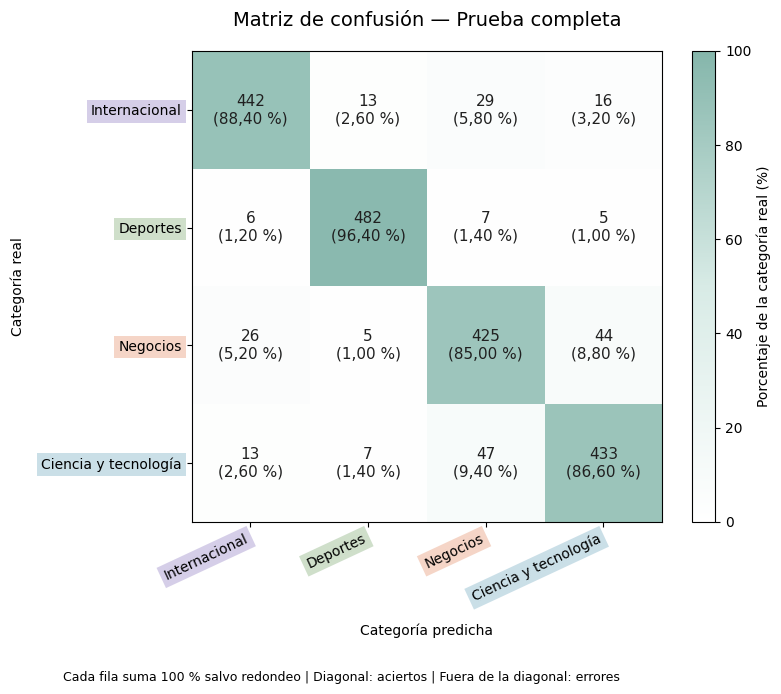

,Categoría real,Predicción incorrecta,Noticias,Porcentaje de la clase real (%)
0,Sci_Tech,Business,47,9.4
1,Business,Sci_Tech,44,8.8
2,World,Business,29,5.8
3,Business,World,26,5.2
4,World,Sci_Tech,16,3.2
5,Sci_Tech,World,13,2.6
6,World,Sports,13,2.6
7,Sci_Tech,Sports,7,1.4
8,Sports,Business,7,1.4
9,Sports,World,6,1.2


Predicciones correctas: 1,782
Predicciones incorrectas: 218


In [19]:
#Grafico las predicciones finales sobre el test original.
test_cm = plot_confusion_matrix(
    test_processed["label"],
    test_predictions,
    "Matriz de confusión — Prueba completa",
    "02_matriz_confusion_prueba.png"
)

#Ordeno los errores por categoría real y predicha.
test_confusion_rows = []

for row, actual_class in enumerate(CLASS_ORDER):
    for column, predicted_class in enumerate(CLASS_ORDER):
        count = int(test_cm[row, column])

        if row != column and count > 0:
            test_confusion_rows.append({
                "Categoría real": actual_class,
                "Predicción incorrecta": predicted_class,
                "Noticias": count,
                "Porcentaje de la clase real (%)": (
                    count / test_cm[row].sum() * 100
                )
            })

test_confusions_df = pd.DataFrame(
    test_confusion_rows,
    columns=[
        "Categoría real",
        "Predicción incorrecta",
        "Noticias",
        "Porcentaje de la clase real (%)"
    ]
).sort_values(
    ["Noticias", "Categoría real", "Predicción incorrecta"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(test_confusions_df.round(2))

print(f"Predicciones correctas: {int(np.trace(test_cm)):,}")
print(
    "Predicciones incorrectas:",
    f"{int(test_cm.sum() - np.trace(test_cm)):,}"
)

#Conservo la matriz como tabla para exportarla.
test_cm_df = pd.DataFrame(
    test_cm,
    index=pd.Index(CLASS_ORDER, name="Categoría real"),
    columns=pd.Index(CLASS_ORDER, name="Categoría predicha")
)

### Interpretación de la matriz de prueba

La confusión entre Negocios y Ciencia/Tecnología concentra 91 de los
218 errores (41,74 %): 47 noticias de Ciencia/Tecnología se clasifican
como Negocios y 44 presentan la confusión inversa.

Negocios tiene el menor F1 (0,8433), mientras que Deportes alcanza
el mayor recall (96,40 %). Este patrón es consistente con la validación
y con el solapamiento temático observado en los ejemplos revisados.

El modelo constituye un baseline para comparar con las próximas etapas;
sus parámetros no se modificaron a partir de los resultados del test.

## 11. Dependencias y reproducibilidad

Registramos las versiones utilizadas y generamos requirements.txt
para reproducir el entorno. La partición utiliza la semilla 42 y
el modelo lingüístico es en_core_web_sm 3.8.0.

In [20]:
from importlib.metadata import version

#Registro las dependencias utilizadas por el notebook.
packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "spacy",
    "tqdm"
]

dependency_versions = {
    package: version(package)
    for package in packages
}

requirements_lines = [
    f"{package}==package_version"
    .replace("package_version", package_version)
    for package, package_version in dependency_versions.items()
]

#Incluyo el modelo de inglés para conservar su versión.
model_version = nlp.meta["version"]

model_requirement = (
    "en-core-web-sm @ "
    "https://github.com/explosion/spacy-models/releases/download/"
    f"en_core_web_sm-{model_version}/"
    f"en_core_web_sm-{model_version}-py3-none-any.whl"
)

requirements_content = (
    "\n".join(requirements_lines + [model_requirement]) + "\n"
)

requirements_path = PROJECT_DIR / "requirements.txt"
requirements_path.write_text(requirements_content, encoding="utf-8")

print(requirements_content)
print(f"Versión de Python: {sys.version.split()[0]}")
print(f"Archivo generado: {requirements_path}")

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
spacy==3.8.18
tqdm==4.67.3
en-core-web-sm @ https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl

Versión de Python: 3.13.18
Archivo generado: /content/ag-news-text-classification/requirements.txt


## 12. Exportación de resultados

Guardamos los experimentos, las métricas, las matrices de confusión,
los ejemplos de preprocesamiento y los controles de coincidencias
para documentar la entrega y facilitar su revisión.

In [21]:
import json
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

#Guardo las tablas conservando sus nombres de columnas.
tables_to_export = {
    "experimentos_tfidf.csv": comparison_df,
    "controles_iniciales.csv": quality_summary,
    "distribucion_particiones.csv": split_summary,
    "ejemplos_preprocesamiento.csv": preprocessing_examples,
    "controles_residuos.csv": residual_summary,
    "duplicados_entrenamiento.csv": duplicate_summary,
    "confusiones_validacion.csv": validation_confusions_df,
    "ejemplos_errores_validacion.csv": error_examples,
    "coincidencias_train_test.csv": overlap_review,
    "comparacion_test.csv": test_comparison_df,
    "confusiones_test.csv": test_confusions_df
}

for filename, table in tables_to_export.items():
    table.to_csv(
        TABLES_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

#Conservo las categorías que están en el índice de los reportes.
for filename, table in [
    ("reporte_validacion.csv", validation_report_df),
    ("reporte_test_completo.csv", test_report_df),
    ("reporte_test_sin_coincidencias.csv", test_independent_report_df)
]:
    table.to_csv(
        TABLES_DIR / filename,
        index=True,
        index_label="Categoría o métrica",
        encoding="utf-8-sig"
    )

#Guardo las matrices de confusión como tablas.
validation_cm_df = pd.DataFrame(
    validation_cm,
    index=pd.Index(CLASS_ORDER, name="Categoría real"),
    columns=CLASS_ORDER
)

validation_cm_df.to_csv(
    TABLES_DIR / "matriz_confusion_validacion.csv",
    encoding="utf-8-sig"
)

test_cm_df.to_csv(
    TABLES_DIR / "matriz_confusion_test.csv",
    encoding="utf-8-sig"
)

#Conservo el índice original para localizar cada noticia de prueba.
test_predictions_df.to_csv(
    TABLES_DIR / "predicciones_test.csv",
    index=True,
    index_label="Fila prueba",
    encoding="utf-8-sig"
)

#Documento la configuración y los resultados principales.
experiment_summary = {
    "dataset": "AG News — muestra de la cátedra",
    "semilla": SEED,
    "documentos_entrenamiento_total": len(train_processed),
    "documentos_entrenamiento_interno": len(train_internal),
    "documentos_validacion": len(validation_df),
    "documentos_test": len(test_processed),
    "coincidencias_procesadas_train_test": overlapping_test_documents,
    "configuracion_seleccionada": best_experiment_id,
    "max_features": final_pipeline.named_steps["tfidf"].max_features,
    "ngram_range": list(
        final_pipeline.named_steps["tfidf"].ngram_range
    ),
    "clasificador": "LogisticRegression",
    "solver": final_pipeline.named_steps["classifier"].solver,
    "C": final_pipeline.named_steps["classifier"].C,
    "max_iter": final_pipeline.named_steps["classifier"].max_iter,
    "f1_macro_validacion": float(
        comparison_df.loc[0, "F1 macro validación"]
    ),
    "metricas_test": test_comparison_df.to_dict(orient="records"),
    "version_python": sys.version.split()[0],
    "dependencias": dependency_versions,
    "modelo_spacy": "en_core_web_sm",
    "version_modelo_spacy": model_version
}

with (RESULTS_DIR / "resumen_experimento.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(
        experiment_summary,
        file,
        ensure_ascii=False,
        indent=2
    )

#Verifico los archivos esenciales antes de comprimir.
required_outputs = [
    requirements_path,
    FIGURES_DIR / "01_matriz_confusion_validacion.png",
    FIGURES_DIR / "02_matriz_confusion_prueba.png",
    TABLES_DIR / "experimentos_tfidf.csv",
    TABLES_DIR / "reporte_test_completo.csv",
    TABLES_DIR / "reporte_test_sin_coincidencias.csv",
    RESULTS_DIR / "resumen_experimento.json"
]

for path in required_outputs:
    if not path.is_file():
        raise FileNotFoundError(f"No se encontró: {path}")

#Empaqueto los resultados y las dependencias.
zip_path = Path("/content/preentrega_3_resultados.zip")

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    archive.write(
        requirements_path,
        arcname="requirements.txt"
    )

    for path in sorted(RESULTS_DIR.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(PROJECT_DIR).as_posix()
            )

print("Resultados y dependencias preparados para descargar.")
files.download(str(zip_path))

Resultados y dependencias preparados para descargar.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>